In [55]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import os
import random
import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

from sklearn.preprocessing import StandardScaler

# libs que usamos para construir y entrenar redes neuronales
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input, Dropout
from tensorflow.keras.callbacks import Callback
from tensorflow.keras.utils import plot_model

# Fijar semilla para reproducibilidad
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [56]:
# Carga de Datos
base = "../data/"
train = pd.read_csv(base + "solicitudes_train.csv")
test = pd.read_csv(base + "solicitudes_test.csv")
behaviour = pd.read_csv(base + "comportamiento_bancario.csv")

In [57]:
# Agrupado de Comportamientos
aggregated_behaviour = behaviour.groupby("ID_Usuario").agg(
    avg_monthly_balance=("Saldo_Promedio_Mensual", "mean"),
    max_days_past_due=("Dias_Atraso_Otras_Deudas", "max")
).reset_index()

# JOINS de dataset con lo agrupado
train_merged = train.merge(aggregated_behaviour, on="ID_Usuario", how="left").fillna(0)
test_merged = test.merge(aggregated_behaviour, on="ID_Usuario", how="left").fillna(0)

In [58]:
display(train_merged.head())

display(test_merged.head())

,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,Estado_Final,avg_monthly_balance,max_days_past_due
0,1,12698,7900,0.2333,4461,Consumo,2025-04,1,3567.364783,25
1,2,20744,17400,0.2507,3889,Vivienda,2025-12,1,6070.002273,56
2,3,6830,8600,0.2368,4035,Vehiculo,2025-06,0,168.037273,57
3,4,5722,13300,0.2826,4018,Vehiculo,2025-07,1,7564.528696,53
4,5,24719,6600,0.2314,3357,Otros,2025-01,1,3504.671304,32


,ID_Solicitud,ID_Usuario,Monto_Solicitado,Tasa_Interes,Ingreso_Mensual,Motivo_Prestamo,Fecha_Solicitud,avg_monthly_balance,max_days_past_due
0,32417,27074,2300,0.2771,2596,Consumo,2026-01,2104.447500,50
1,32418,28172,10900,0.3291,6905,Consumo,2026-01,21749.880455,43
2,32419,27547,1300,0.2485,3707,Educacion,2026-01,1211.650435,67
3,32420,27689,1600,0.2699,3314,Consumo,2026-01,7926.885455,61
4,32421,26219,900,0.2317,3870,Educacion,2026-01,6129.496087,53


In [59]:
# Columnas categóricas (One-Hot encode para que funcionen con árboles) 
train_encoded = pd.get_dummies(train_merged, columns=["Motivo_Prestamo"], drop_first=True)
test_encoded = pd.get_dummies(test_merged, columns=["Motivo_Prestamo"], drop_first=True)

# Estructuramos test_encoded al formato del train
test_encoded = test_encoded.reindex(columns=train_encoded.columns.drop("Estado_Final"), fill_value=0)

In [60]:
from sklearn.preprocessing import StandardScaler

# Columnas de relleno, no útiles para entrenamiento
drop_columns = ["ID_Solicitud", "ID_Usuario", "Fecha_Solicitud"]

# Separación de X (variables predictorias) e Y (objetivo)
X_train = train_encoded.drop(columns=drop_columns + ["Estado_Final"])
y_train = train_encoded["Estado_Final"]
X_test = test_encoded.drop(columns=drop_columns)

# Inicializar y aplicar StandardScaler
scaler = StandardScaler()

# Se hace fit_transform en train para aprender la media y desviación estándar
X_train_scaled = scaler.fit_transform(X_train)

# Se hace transform en test usando la información aprendida de train
X_test_scaled = scaler.transform(X_test)

In [61]:
# Fijar semilla antes de definir y entrenar el modelo
tf.keras.utils.set_random_seed(42)

from sklearn.neural_network import MLPClassifier
model = Sequential([
    Input(shape=(X_train_scaled.shape[1],)),
    
    # Primera capa oculta: amplia para captar las relaciones iniciales
    Dense(64, activation='relu'),
    Dropout(0.35),
    
    # Segunda capa oculta: más pequeña para destilar la información importante
    Dense(32, activation='relu'),
    Dropout(0.25),
    
    # Capa de salida: 1 neurona con sigmoid para obtener una probabilidad entre 0 y 1
    Dense(1, activation='sigmoid'),
])

# Compilación y entrenamiento
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

model.summary()

model_weights_at_epochs = {}

class OurCustomCallback(Callback):
    def on_epoch_end(self, epoch, logs=None):
        model_weights_at_epochs[epoch] = self.model.get_weights()
        
history = model.fit(
    X_train_scaled,
    y_train, epochs=50,
    batch_size=32,
    validation_split=0.2,
    callbacks=[OurCustomCallback()]
)

# Predicción de probabilidades para el ROI
test["repayment_probability"] = model.predict(X_test_scaled).flatten()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_20 (Dense)                │ (None, 64)             │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_22 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,881 (11.25 KB)

 Trainable params: 2,881 (11.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
811/811 ━━━━━━━━━━━━━━━━━━━━ 1s 441us/step - accuracy: 0.8430 - loss: 0.3943 - val_accuracy: 0.8532 - val_loss: 0.3546
Epoch 2/50
811/811 ━━━━━━━━━━━━━━━━━━━━ 0s 360us/step - accuracy: 0.8531 - loss: 0.3635 - val_accuracy: 0.8529 - val_loss: 0.3517
Epoch 3/50
811/811 ━━━━━━━━━━━━━━━━━━━━ 0s 348us/step - accuracy: 0.8554 - loss: 0.3589 - val_accuracy: 0.8547 - val_loss: 0.3504
Epoch 4/50
811/811 ━━━━━━━━━━━━━━━━━━━━ 0s 350us/step - accuracy: 0.8543 - loss: 0.3563 - val_accuracy: 0.8561 - val_loss: 0.3500
Epoch 5/50
811/811 ━━━━━━━━━━━━━━━━━━━━ 0s 368us/step - accuracy: 0.8559 - loss: 0.3529 - val_accuracy: 0.8564 - val_loss: 0.3488
Epoch 6/50
811/811 ━━━━━━━━━━━━━━━━━━━━ 0s 370us/step - accuracy: 0.8572 - loss: 0.3499 - val_accuracy: 0.8581 - val_loss: 0.3489
Epoch 7/50
811/811 ━━━━━━━━━━━━━━━━━━━━ 0s 368us/step - accuracy: 0.8591 - loss: 0.3499 - val_accuracy: 0.8578 - val_loss: 0.3484
Epoch 8/50
811/811 ━━━━━━━━━━━━━━━━━━━━ 0s 382us/step - accuracy: 0.8602 - loss: 0.3468 - 

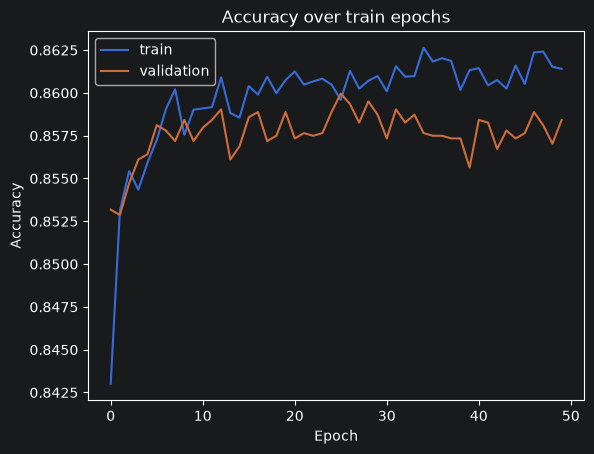

In [62]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy over train epochs')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(loc='upper left')
plt.show()

In [63]:
gain = test["Monto_Solicitado"] * test["Tasa_Interes"]
loss = test["Monto_Solicitado"]

# Ganancia Esperada
# SI Resultado > 0: La operación es rentable en promedio.
# SINO La tasa de interés no compensa el riesgo de impago (prestar genera pérdidas a largo plazo)
test["expected_profit"] = (test["repayment_probability"] * gain) - ((1 - test["repayment_probability"]) * loss)

# Retorno de inversión (punto óptimo entre seguridad y ganancia)
# Evita que todos los préstamos sean pocos de mucho valor, diversifica
test["expected_roi"] = test["expected_profit"] / test["Monto_Solicitado"]

In [64]:
# Filtra solo los que tienen esperanza matemática positiva
candidates = test[test["expected_profit"] > 0].copy()

# Ordena ESTRICTAMENTE por mayor retorno de inversion
candidates = candidates.sort_values(by="expected_roi", ascending=False)

In [65]:
# Asigna el presupuesto a los más seguros hasta agotar los 2.000.000 USD
candidates["cumulative_amount"] = candidates["Monto_Solicitado"].cumsum()

BUDGET_LIMIT = 2000000
# Obtiene los préstamos hasta llegar al acumulado que no excede el capital inicial
approved_loans = candidates[candidates["cumulative_amount"] <= BUDGET_LIMIT]
# Obtiene los ids de préstamos
approved_ids = approved_loans["ID_Solicitud"].tolist()

In [67]:
# Colocar estados de préstamos en test
test["Decision_Aprobacion"] = 0
test.loc[test["ID_Solicitud"].isin(approved_ids), "Decision_Aprobacion"] = 1

# Generación del CSV 
sumbission = test[["ID_Solicitud", "Decision_Aprobacion"]]
sumbission.to_csv("submissions/mas_probable_cobro_ROIMLP.csv", index=False)

In [68]:
# Métricas de control
total_allocated = test[test["Decision_Aprobacion"] == 1]["Monto_Solicitado"].sum()
min_prob = approved_loans["repayment_probability"].min()
avg_prob = approved_loans["repayment_probability"].mean()

print(f"Total préstamos aprobados: {len(approved_ids)}")
print(f"Capital total prestado: ${total_allocated:,.2f} USD")
print(f"Presupuesto restante: ${BUDGET_LIMIT - total_allocated:,.2f} USD")
print(f"Probabilidad de pago más baja aprobada: {min_prob:.4f}")
print(f"Probabilidad de pago promedio del portafolio: {avg_prob:.4f}")

Total préstamos aprobados: 616
Capital total prestado: $1,999,700.00 USD
Presupuesto restante: $300.00 USD
Probabilidad de pago más baja aprobada: 0.9261
Probabilidad de pago promedio del portafolio: 0.9843
